# CE23: independent SOLO depth fits from IN2023_V06 ADCP

CE23 is cyclonic (expected relative vorticity negative). Start with C1, **17 October 2023 13:30 to 18 October 2023 13:30 UTC**, using the approximate initial centre **154.3°E, 37.9°S**. Additional independent crossings can be added in `transects.json` with their own complete `fit_by_transect` blocks in `CE23_solo.json`.

Only crossings within the configured CE23 study window are allowed. Each crossing is fitted separately at actual measured depths. Accepted inner centres seed the next depth; Gaussian acceptance is separate. “Surface” denotes the shallowest observed bin, not sea level. New notebooks have no executed scientific outputs; inherited fit settings are editable starting values, not CE23-validated choices.


In [109]:
from pathlib import Path
import importlib.util
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Find the shared helper from the study folder or the UNSW-PhD repository root.
candidates = [Path.cwd(), *Path.cwd().parents,
              Path.cwd() / "seacofs_eddy_tilt_analysis" / "observations"]
OBSERVATIONS_DIR = next(p for p in candidates
                        if p.name == "observations" and (p / "esp_depth_tools.py").is_file())
spec = importlib.util.spec_from_file_location("esp_depth_tools", OBSERVATIONS_DIR / "esp_depth_tools.py")
esp = importlib.util.module_from_spec(spec)
spec.loader.exec_module(esp)


## Controls

Edit `CE23_solo.json` for independent fit settings and `transects.json` for crossing windows and origins. `active_transect` selects detailed plots. Run this notebook and its export before CE23 LATTE; rerun both after changing the SOLO seed fits.


In [110]:
EDDY = "CE23"
STUDY_DIR = OBSERVATIONS_DIR / "MNF_IN2023_V06_adcp_trawler"
CONFIG_PATH = STUDY_DIR / "CE23_solo.json"
CONFIG = json.loads(CONFIG_PATH.read_text())
TRANSECTS_PATH = STUDY_DIR / CONFIG["transects_config"]
BACKEND_PATH = Path(CONFIG["backend_path"])
ACTIVE_TRANSECT = CONFIG["active_transect"]
DATA_PATH, transects, adcp = esp.load_study(
    TRANSECTS_PATH, EDDY, load_adcp=False)
WINDOW_START = pd.Timestamp(CONFIG["time_window_utc"]["start"])
WINDOW_END = pd.Timestamp(CONFIG["time_window_utc"]["end"])
if any(t.tzinfo is None or t.utcoffset().total_seconds() != 0 for t in (WINDOW_START, WINDOW_END)) or WINDOW_END <= WINDOW_START:
    raise ValueError("time_window_utc must contain increasing UTC timestamps")
for ident, crossing in transects.iterrows():
    if not WINDOW_START <= pd.Timestamp(crossing.start) < pd.Timestamp(crossing.end) <= WINDOW_END:
        raise ValueError(f"{ident}: crossing lies outside the CE23 study window")
if set(CONFIG["fit_by_transect"]) != set(transects.index):
    raise ValueError("Provide exactly one fit_by_transect block per CE23 crossing")
if ACTIVE_TRANSECT not in transects.index:
    raise ValueError(f"ACTIVE_TRANSECT must be one of {list(transects.index)}")
MIN_ATTENDANCE = CONFIG["min_attendance"]
FIT_BY_TRANSECT = {ident: CONFIG["fit_by_transect"][ident] for ident in transects.index}
MAP_DEPTHS = tuple(CONFIG["map_depths"])
HALF_WIDTH_KM = CONFIG["half_width_km"]
VELOCITY_LIMIT = CONFIG["velocity_limit"]
display(transects)


ValueError: C1: crossing lies outside the CE23 study window

selected_rows                               92786
used_rows                                   92786
unique_times                                 1732
start_utc               2023-10-17 10:27:31+00:00
end_utc                 2023-10-21 22:27:30+00:00
depth_range_m                       [18.0, 414.4]
missing_avg_qc                              92786
zero_attendance_rows                        55241
min_attendance                               None
origin_lon_lat                     (154.3, -37.9)
bounds_lon_lat                               None
Name: CE23 overview selection, dtype: object

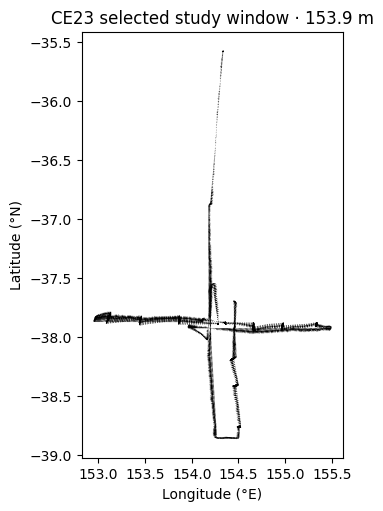

In [ ]:
# Overview uses only the configured CE23 time window; no geographic filter.
overview, overview_coverage, overview_audit = esp.load_observations(
    DATA_PATH, WINDOW_START, WINDOW_END,
    (float(transects.iloc[0].lon), float(transects.iloc[0].lat)),
    min_attendance=MIN_ATTENDANCE)
target_depth = overview.depth.value_counts().idxmax()
df = overview.loc[overview.depth.eq(target_depth)]
fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
ax.quiver(df.lon, df.lat, df.u, df.v)
ax.set(xlabel="Longitude (°E)", ylabel="Latitude (°N)",
       title=f"CE23 selected study window · {target_depth:g} m")
ax.set_aspect(1 / np.cos(np.deg2rad(df.lat.mean())))
display(pd.Series(overview_audit, name="CE23 overview selection"))
plt.show()


## Fit all crossings independently

Each crossing uses its own UTC window, origin and fit settings. Accepted inner centres seed subsequent measured depths; failed levels remain gaps. Gaussian reconstruction requires its own acceptance checks. Radius-tracking options follow the same rules as the 2015 notebooks. No averaging across crossings, depth interpolation, background subtraction or movement correction is performed.


path                 /home/z5297792/ESP_zonodo/functions.py
sha256    10208a788eea38e9451edc3a2f31aaa351f043e3cb6ed5...
Name: ESP backend, dtype: object

,times,bins,inner_fits,gaussian_fits,inner_min_m,inner_max_m,gaussian_max_m,surface_status
transect,,,,,,,,
C1,549,98,90,90,18.0,414.4,414.4,ok


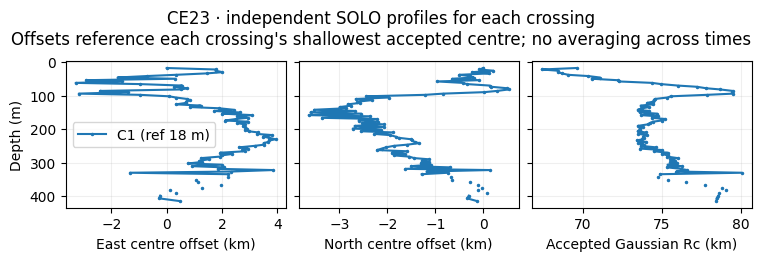

In [ ]:
backend, backend_info = esp.load_backend(BACKEND_PATH)
runs, summary, all_results = esp.fit_transects(
    DATA_PATH, transects, backend, min_attendance=MIN_ATTENDANCE,
    fit_by_transect=FIT_BY_TRANSECT)
display(pd.Series(backend_info, name="ESP backend"))
display(summary)
esp.plot_transect_comparison(runs, EDDY)
plt.show()


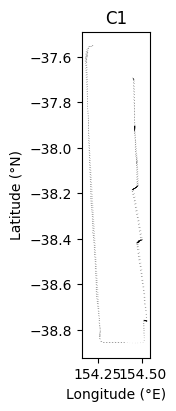

In [ ]:
ncols = min(3, len(transects))
nrows = int(np.ceil(len(transects) / ncols))
fig, axs = plt.subplots(nrows, ncols, figsize=(4*ncols, 4*nrows),
                        constrained_layout=True, squeeze=False)
for ax, ident in zip(axs.flat, transects.index):
    crossing_run = runs[ident]
    sample = crossing_run["samples"][crossing_run["results"].depth_m.min()]
    ax.quiver(sample.lon, sample.lat, sample.u, sample.v)
    ax.set(title=ident, xlabel="Longitude (°E)", ylabel="Latitude (°N)")
    ax.set_aspect(1 / np.cos(np.deg2rad(sample.lat.mean())))
for ax in list(axs.flat)[len(transects):]:
    ax.set_axis_off()
plt.show()


## Select a crossing for detailed plots

Change `ACTIVE_TRANSECT` here and rerun this and the plotting cells to inspect another crossing without repeating the fits. The audit shows actual time/depth coverage. Centre offsets reference this crossing's shallowest accepted inner fit; positive east/north offsets indicate displacement toward those directions at depth.


selected_rows                                                       32533
used_rows                                                           32533
unique_times                                                          549
start_utc                                       2023-10-17 10:32:30+00:00
end_utc                                         2023-10-18 16:27:31+00:00
depth_range_m                                               [18.0, 414.4]
missing_avg_qc                                                      32533
zero_attendance_rows                                                16850
min_attendance                                                       None
origin_lon_lat                                             (154.3, -37.9)
bounds_lon_lat                                                       None
fit_settings            {'core_radius': 10000.0, 'outer_radius': 65000...
Name: C1, dtype: object

SOLO: 90/98 accepted inner fits; 90/98 accepted Gaussian reconstructions.
status
insufficient_search     8
ok                     90
Centre offsets reference the shallowest accepted fit: 18 m.
Reconstructed measured levels: 18–414.4 m (gaps retained).
The ADCP sampling limit is not an estimate of the eddy bottom. R² is in-sample.


,depth_m,status,n_obs,n_core,inner_valid,valid,xc_lon,yc_lat,inner_R2,Rc_m,peak_bracketed,vector_R2
0,18.0,ok,360,60,True,True,154.2572,-37.8748,0.7851,69625.7513,True,0.8838
1,22.4,ok,360,58,True,True,154.2774,-37.8756,0.8520,67427.8585,True,0.8682
2,26.0,ok,360,59,True,True,154.2775,-37.8729,0.8926,68434.2209,True,0.9056
3,30.4,ok,360,58,True,True,154.2802,-37.8769,0.8259,68469.8222,True,0.9004
4,34.0,ok,356,55,True,True,154.2739,-37.8737,0.9056,68682.2647,True,0.9068
...,...,...,...,...,...,...,...,...,...,...,...,...
93,390.4,ok,351,54,True,True,154.2609,-37.8741,0.9028,78613.3859,True,0.8341
94,394.0,insufficient_search,4,0,False,False,NaN,NaN,NaN,NaN,False,NaN
95,398.4,ok,354,54,True,True,154.2545,-37.8776,0.8884,78553.6128,True,0.8337
96,406.4,ok,353,54,True,True,154.2542,-37.8778,0.9034,78444.0503,True,0.8363


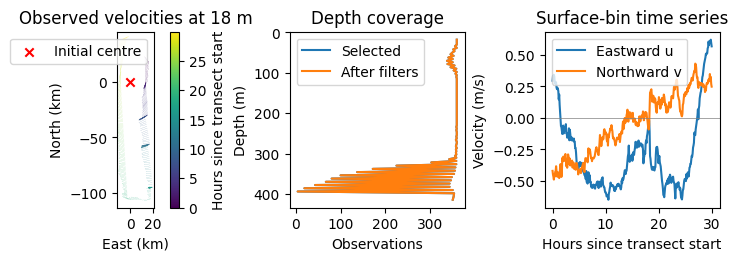

In [ ]:
# ACTIVE_TRANSECT = "C1"  # Select another configured CE23 crossing here.
run = runs[ACTIVE_TRANSECT]
data, coverage = run["data"], run["coverage"]
results, samples = run["results"], run["samples"]
display(pd.Series(run["audit"], name=ACTIVE_TRANSECT))
esp.report(results)
columns = ["depth_m", "status", "n_obs", "n_core", "inner_valid", "valid",
           "xc_lon", "yc_lat", "inner_R2", "Rc_m", "peak_bracketed", "vector_R2"]
with pd.option_context("display.max_rows", 60):
    display(results[columns].round(4))
esp.plot_sampling(data, coverage, quiv_scale=3)
plt.show()


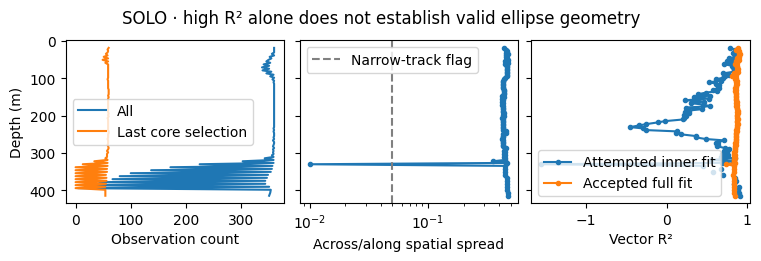

In [ ]:
esp.plot_diagnostics(results)
plt.show()


## Vertical centre trajectory and parameters

Offset profiles use geographic east/north coordinates and increase from shallow to deep. They are distinct from the climatology's saved deep-to-shallow delta tilt. SOLO imposes axis ratio 1; `zeta = 2*Omega`. Gaussian `Rc` is not the same quantity as a paper-reported eddy radius or diameter. A failure in the outer stage does not erase an accepted inner centre.


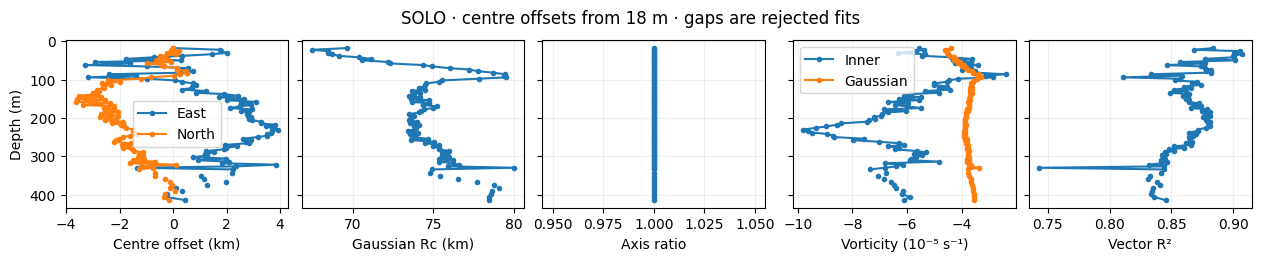

In [ ]:
esp.plot_profiles(results)
plt.show()


## Horizontal reconstructions

Plots use the nearest measured level to each request, keeping failed levels visible. Black arrows are observed; grey arrows are reconstructed. Red marks the centre and `rho=Rc/sqrt(2)` contour where a Gaussian fit is accepted. Reconstruction off the sampled line is model-based extrapolation.


0.84 km mean spacing


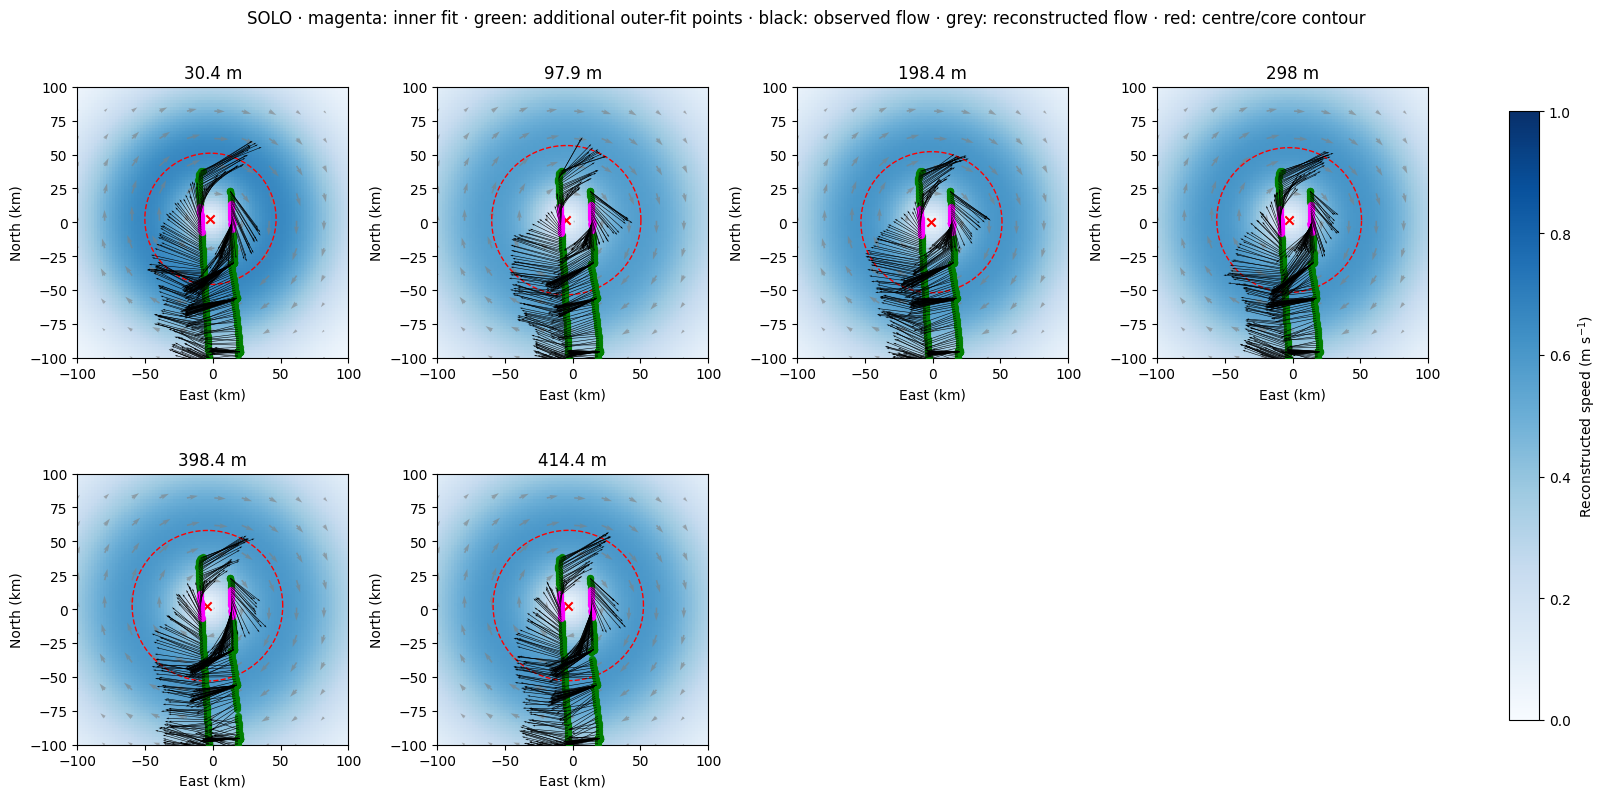

In [ ]:
esp.plot_maps(results, samples, backend, depths=MAP_DEPTHS,
              half_width_km=HALF_WIDTH_KM, speed_max=VELOCITY_LIMIT, quiv_width=0.002, quiv_scale=3)
plt.show()


## Surface satellite velocity and SOLO samples

OceanCurrent daily geostrophic velocity is interpolated to the middle observed timestamp of the selected crossing. The shallowest measured ADCP bin is overlaid. Daily maps are downloaded and cached beside the CSV if missing. This optional plot requires satellite access and does not affect the fits or exports.


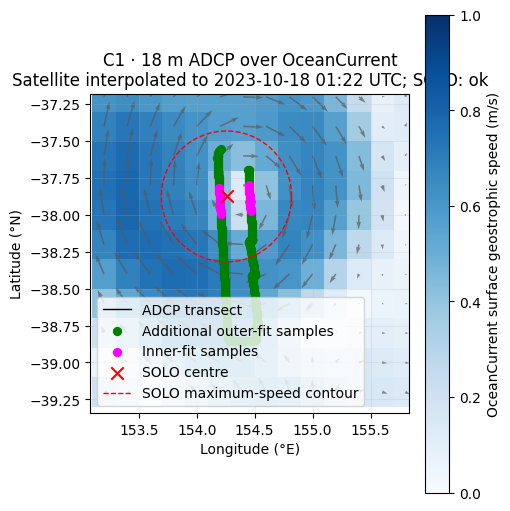

In [ ]:
fig, ax = esp.plot_solo_satellite_overlay(
    data, results, samples, DATA_PATH.parent, ACTIVE_TRANSECT,
    half_width_km=120, speed_max=VELOCITY_LIMIT)
plt.show()


## Three-dimensional structure

The centreline uses accepted inner fits; stacked contours and horizontal flow arrows appear only where the Gaussian stage is accepted. Where no radius is accepted, only the centreline is shown. Vertical scale is exaggerated. The deepest fitted bin does not establish the eddy bottom.


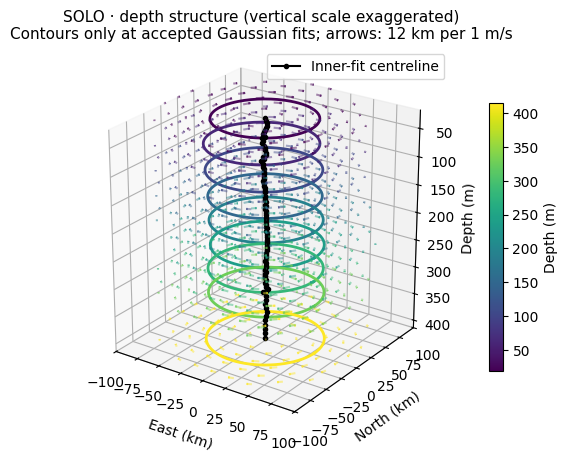

In [ ]:
esp.plot_3d(results, backend, half_width_km=HALF_WIDTH_KM)
plt.show()


## Zonal and meridional sections

Fixed planes pass through the shallowest accepted inner centre. The zonal plane shows northward velocity `v`, and the meridional plane eastward velocity `u`. The centre paths are projections onto the planes; deeper centres need not lie within them. White depth rows are rejected Gaussian fits, with no interpolation across them. A crossing with no accepted Gaussian reconstruction produces an explanatory panel.


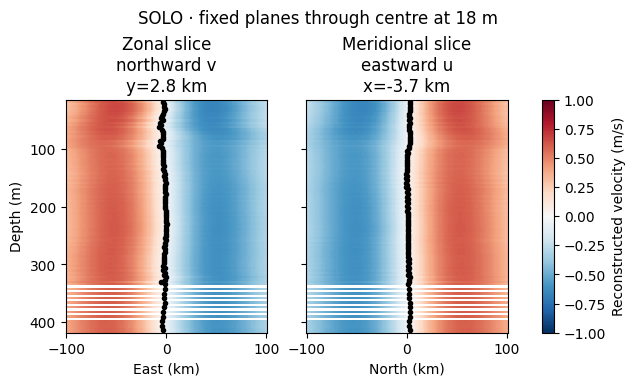

In [ ]:
esp.plot_sections(results, backend, half_width_km=HALF_WIDTH_KM,
                  speed_max=VELOCITY_LIMIT)
plt.show()


## Export to scratch

Export all transects together, retaining IDs, actual UTC bounds, coordinates, depth support and failure statuses. Settings and per-crossing selection audits accompany the table.


In [ ]:
SAVE_RESULTS = CONFIG["save_results"]
if SAVE_RESULTS:
    import json
    output = DATA_PATH.parent / "outputs"
    output.mkdir(parents=True, exist_ok=True)
    all_results.to_csv(output / f"{EDDY.lower()}_solo_depth_fits.csv", index=False)
    provenance = dict(eddy=EDDY, config_path=str(CONFIG_PATH), transects_config_path=str(TRANSECTS_PATH), data_path=str(DATA_PATH),
                      backend=backend_info, time_window_utc=CONFIG["time_window_utc"],
                      fit_by_transect=FIT_BY_TRANSECT,
                      transects=transects.reset_index().to_dict(orient="records"),
                      selection={key: value["audit"] for key, value in runs.items()})
    (output / f"{EDDY.lower()}_solo_provenance.json").write_text(
        json.dumps(provenance, indent=2, default=str))


## Along-track bin sensitivity

Set `along_track_bin_km` in `CE23_solo.json` to the widths to compare for `ACTIVE_TRANSECT`. Each occupied along-track cell contributes one mean east/north velocity vector at each measured depth. The original fit stays unchanged; separate crossings and visits are never combined. Centre offsets in this comparison all use the **original shallowest accepted centre** as one common reference, so a surface shift caused by binning remains visible. `Rc` is shown only for accepted Gaussian fits; vorticity is from accepted inner fits.


,vectors,inner_depths,Rc_depths
bin,,,
Original,32533,90,90
2 km,6794,90,90
3 km,4572,90,90
4 km,3460,90,90
5 km,2809,54,54


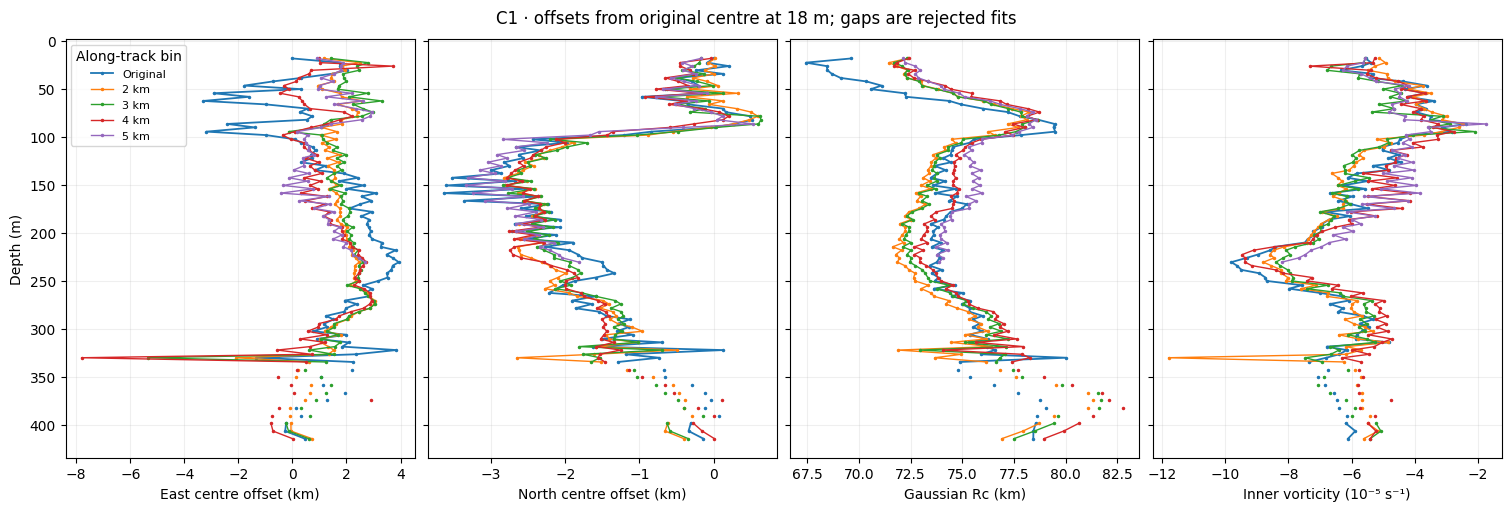

In [ ]:
BIN_WIDTHS_KM = json.loads(CONFIG_PATH.read_text())["along_track_bin_km"]
if len(BIN_WIDTHS_KM) != len(set(BIN_WIDTHS_KM)):
    raise ValueError("along_track_bin_km must contain unique widths")
bin_fits = {"Original": results}
bin_counts = [{"bin": "Original", "vectors": len(data),
               "inner_depths": int(results.inner_valid.sum()), "Rc_depths": int(results.valid.sum())}]
for width_km in BIN_WIDTHS_KM:
    binned = esp.bin_solo_along_track(data, width_km)
    fitted, _ = esp.fit_depths(binned, backend, "SOLO",
                               depth_levels=coverage.index, **runs[ACTIVE_TRANSECT]["fit_settings"])
    label = f"{width_km:g} km"
    bin_fits[label] = fitted
    bin_counts.append({"bin": label, "vectors": len(binned),
                       "inner_depths": int(fitted.inner_valid.sum()),
                       "Rc_depths": int(fitted.valid.sum())})
display(pd.DataFrame(bin_counts).set_index("bin"))
esp.plot_solo_binning_comparison(bin_fits, ACTIVE_TRANSECT)
plt.show()
